Accuracy : 0.374
Balanced accuracy : 0.507
Précision anomalies : 0.693
Rappel anomalies : 0.102
F1 anomalies : 0.178
Accuracy de référence : 0.664

Rapport de classification :
              precision    recall  f1-score   support

      Normal       0.34      0.91      0.49       684
    Anomalie       0.69      0.10      0.18      1349

    accuracy                           0.37      2033
   macro avg       0.52      0.51      0.34      2033
weighted avg       0.57      0.37      0.28      2033

Matrice de confusion :
[[ 623   61]
 [1211  138]]


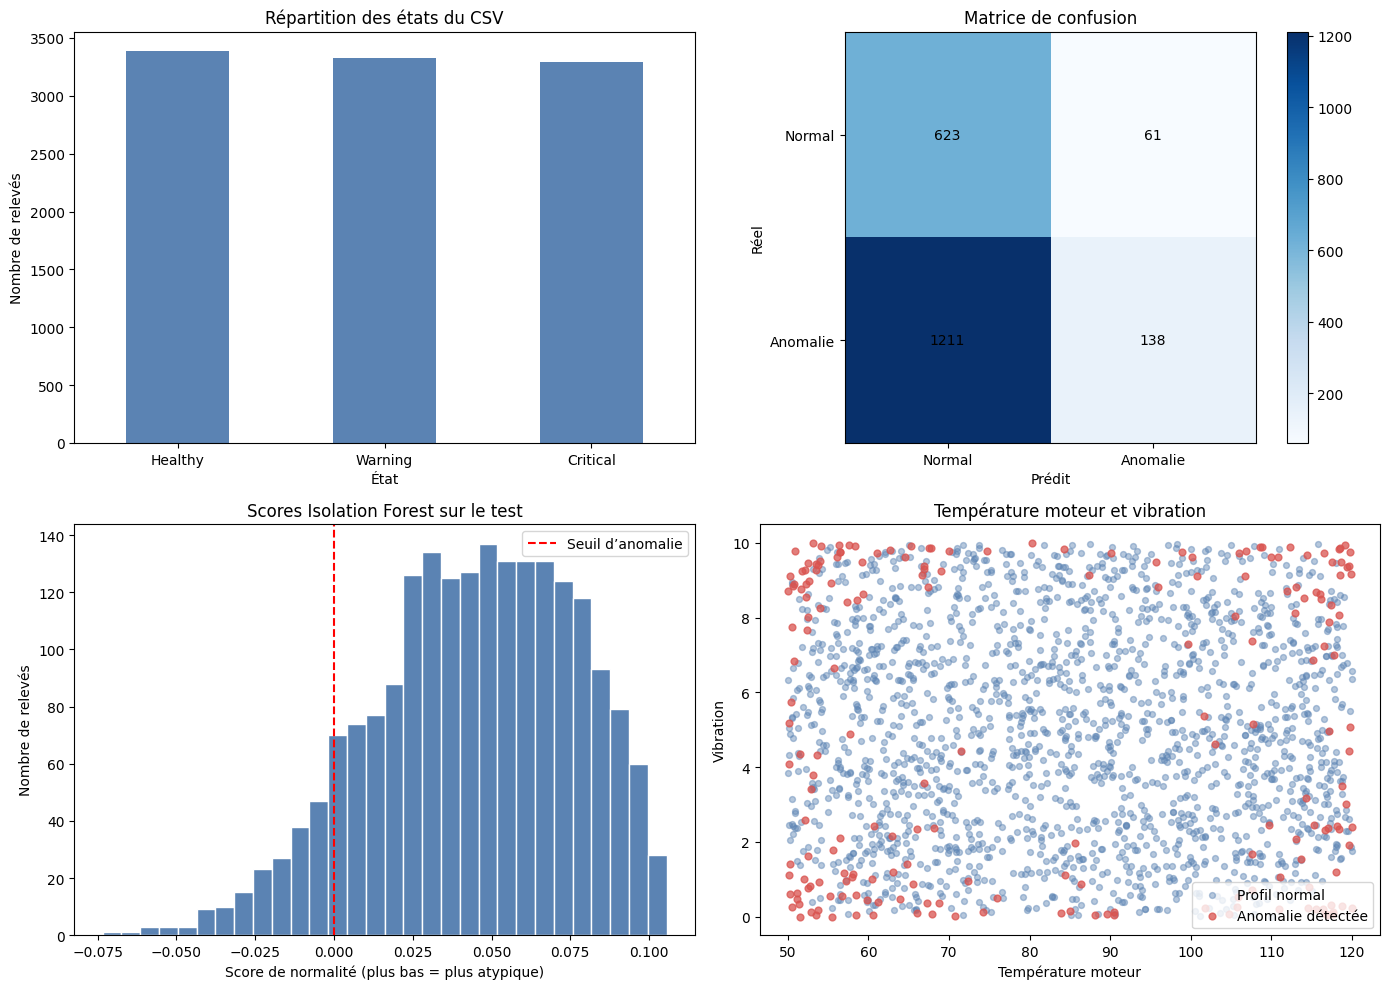


Taux d’anomalies détectées par état :
State
Critical    0.103
Healthy     0.100
Warning     0.106
Name: Anomalie_detectee, dtype: float64

Simulation : {'détection': 'profil normal', 'score_normalité': 0.0525, 'rareté_relative_sur_100': np.float64(43.1)}


['isolation_forest_mining.joblib']

In [2]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)


df = pd.read_csv("digitalTwin.csv")

FEATURES = ["HealthIndex", "EngineTemp", "Vibration", "Pressure"]
GROUP = "Equipment"
TARGET = "State"

df = df.dropna(subset=[GROUP, TARGET, *FEATURES]).copy()
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=FEATURES)

X = df[FEATURES].astype(float)
groups = df[GROUP].astype(str)


splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(X, groups=groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
state_train = df[TARGET].iloc[train_idx].astype(str).str.strip().str.casefold()
state_test = df[TARGET].iloc[test_idx].astype(str).str.strip().str.casefold()


healthy_mask = state_train.eq("healthy").to_numpy()
X_normal_train = X_train.iloc[np.flatnonzero(healthy_mask)]

if len(X_normal_train) < 20:
    X_normal_train = X_train

contamination = 0.10

model_test = IsolationForest(
    n_estimators=300,
    contamination=contamination,
    random_state=42,
    n_jobs=-1,
)
model_test.fit(X_normal_train)


pred_test = model_test.predict(X_test)
score_test = model_test.decision_function(X_test)


y_true = (state_test != "healthy").astype(int).to_numpy()
y_pred = (pred_test == -1).astype(int)

print("Accuracy :", round(accuracy_score(y_true, y_pred), 3))
print("Balanced accuracy :", round(balanced_accuracy_score(y_true, y_pred), 3))
print("Précision anomalies :", round(precision_score(y_true, y_pred, zero_division=0), 3))
print("Rappel anomalies :", round(recall_score(y_true, y_pred, zero_division=0), 3))
print("F1 anomalies :", round(f1_score(y_true, y_pred, zero_division=0), 3))


y_train_ref = (state_train != "healthy").astype(int)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train_ref)
print("Accuracy de référence :", round(accuracy_score(y_true, baseline.predict(X_test)), 3))

print("\nRapport de classification :")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Anomalie"],
    zero_division=0,
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
print("Matrice de confusion :")
print(cm)


fig, axes = plt.subplots(2, 2, figsize=(14, 10))


df[TARGET].value_counts().plot(
    kind="bar",
    ax=axes[0, 0],
    color="#5B83B3",
)
axes[0, 0].set_title("Répartition des états du CSV")
axes[0, 0].set_xlabel("État")
axes[0, 0].set_ylabel("Nombre de relevés")
axes[0, 0].tick_params(axis="x", rotation=0)

image = axes[0, 1].imshow(cm, cmap="Blues")
axes[0, 1].set_title("Matrice de confusion")
axes[0, 1].set_xticks([0, 1], labels=["Normal", "Anomalie"])
axes[0, 1].set_yticks([0, 1], labels=["Normal", "Anomalie"])
axes[0, 1].set_xlabel("Prédit")
axes[0, 1].set_ylabel("Réel")

for row in range(2):
    for col in range(2):
        axes[0, 1].text(
            col,
            row,
            cm[row, col],
            ha="center",
            va="center",
            color="black",
        )

fig.colorbar(image, ax=axes[0, 1])


axes[1, 0].hist(score_test, bins=30, color="#5B83B3", edgecolor="white")
axes[1, 0].axvline(0, color="red", linestyle="--", label="Seuil d’anomalie")
axes[1, 0].set_title("Scores Isolation Forest sur le test")
axes[1, 0].set_xlabel("Score de normalité (plus bas = plus atypique)")
axes[1, 0].set_ylabel("Nombre de relevés")
axes[1, 0].legend()


anomaly_mask = pred_test == -1
normal_positions = np.flatnonzero(~anomaly_mask)
anomaly_positions = np.flatnonzero(anomaly_mask)

axes[1, 1].scatter(
    X_test.iloc[normal_positions]["EngineTemp"],
    X_test.iloc[normal_positions]["Vibration"],
    alpha=0.45,
    s=18,
    color="#5B83B3",
    label="Profil normal",
)
axes[1, 1].scatter(
    X_test.iloc[anomaly_positions]["EngineTemp"],
    X_test.iloc[anomaly_positions]["Vibration"],
    alpha=0.75,
    s=24,
    color="#D9534F",
    label="Anomalie détectée",
)
axes[1, 1].set_title("Température moteur et vibration")
axes[1, 1].set_xlabel("Température moteur")
axes[1, 1].set_ylabel("Vibration")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


all_states = df[TARGET].astype(str).str.strip().str.casefold()
all_healthy = all_states.eq("healthy").to_numpy()
X_normal_all = X.iloc[np.flatnonzero(all_healthy)]

if len(X_normal_all) < 20:
    X_normal_all = X

model = IsolationForest(
    n_estimators=300,
    contamination=contamination,
    random_state=42,
    n_jobs=-1,
)
model.fit(X_normal_all)
scores_normaux = np.sort(model.decision_function(X_normal_all))


results = df[[GROUP, TARGET]].copy()
results["Score_normalite"] = model.decision_function(X)
results["Anomalie_detectee"] = model.predict(X) == -1
results.to_csv("isolation_forest_results.csv", index=False, encoding="utf-8-sig")

print("\nTaux d’anomalies détectées par état :")
print(results.groupby(TARGET)["Anomalie_detectee"].mean().round(3))

def simuler_releve(valeurs_capteurs):
    observation = pd.DataFrame([valeurs_capteurs], columns=FEATURES).astype(float)
    score = float(model.decision_function(observation)[0])
    anomalie = int(model.predict(observation)[0]) == -1

    rarete = 100 * (
        1 - np.searchsorted(scores_normaux, score, side="right") / len(scores_normaux)
    )

    return {
        "détection": "ANOMALIE" if anomalie else "profil normal",
        "score_normalité": round(score, 4),
        "rareté_relative_sur_100": round(rarete, 1),
    }

exemple = df.iloc[0][FEATURES].to_dict()
print("\nSimulation :", simuler_releve(exemple))

results.to_csv("isolation_forest_results.csv", index=False, encoding="utf-8-sig")
joblib.dump(model, "isolation_forest_mining.joblib")